<a href="https://colab.research.google.com/github/santhwana27/Machine-Learning-Lab-Programs/blob/main/GMM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## TASK 1: LOAD AND UNDERSTAND THE DATASET

Saving GMM_Lab_Dataset_FINAL.xlsx to GMM_Lab_Dataset_FINAL (4).xlsx


**First 10 Records**

,Record_ID,Feature_1,Feature_2
0,1,27.955,43.791
1,2,25.671,36.404
2,3,20.564,37.704
3,4,26.570,39.699
4,5,27.773,41.462
5,6,19.087,34.235
6,7,22.674,37.352
7,8,24.669,36.034
8,9,28.950,26.449
9,10,34.325,22.493


**Dataset Shape**

,Rows,Columns
0,450,3


**Descriptive Statistics**

,Record_ID,Feature_1,Feature_2
count,450.000000,450.000000,450.000000
mean,225.500000,26.209673,32.714913
std,130.048068,5.267977,6.495383
min,1.000000,16.274000,18.980000
25%,113.250000,20.771500,25.136500
50%,225.500000,26.837500,34.913000
75%,337.750000,30.770000,37.783250
max,450.000000,37.428000,44.637000


**Input Features:** Record_ID, Feature_1

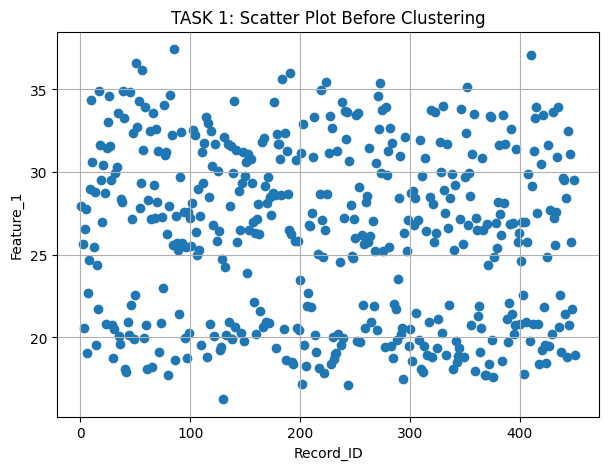

## TASK 2: APPLY GMM CLUSTERING

**Cluster Assignments**

,Record_ID,Feature_1,GMM_Cluster
0,1,27.955,2
1,2,25.671,2
2,3,20.564,2
3,4,26.570,2
4,5,27.773,2
...,...,...,...
445,446,31.086,1
446,447,25.780,1
447,448,21.735,1
448,449,29.532,1


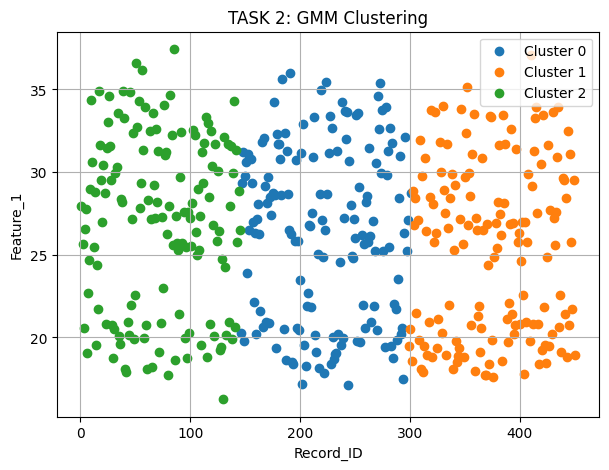

**Gaussian Means**

,Record_ID,Feature_1
0,223.479860,26.268547
1,372.420846,25.412849
2,76.585952,26.966267


**Covariance Matrices**

**Component 0**

,Record_ID,Feature_1
Record_ID,3011.497153,-9.446426
Feature_1,-9.446426,27.622978


...

## TASK 3: SOFT CLUSTERING AND GAUSSIAN DISTRIBUTIONS

**Membership Probabilities — First 10 Observations**

,Component_0,Component_1,Component_2
0,0.000879,3.911682e-13,0.999121
1,0.000925,5.709132e-13,0.999075
2,0.001003,1.140335e-12,0.998997
3,0.000998,6.645568e-13,0.999002
4,0.001032,6.603200e-13,0.998968
5,0.001150,1.951502e-12,0.998850
6,0.001157,1.486430e-12,0.998843
7,0.001187,1.352881e-12,0.998813
8,0.001208,9.614911e-13,0.998792
9,0.001246,6.105092e-13,0.998754


**Uncertain Observations (Maximum Probability < 0.60)**

,Component_0,Component_1,Component_2,Maximum_Probability
137,0.409419,0.000017,0.590564,0.590564
140,0.447900,0.000022,0.552078,0.552078
141,0.429010,0.000011,0.570980,0.570980
142,0.457445,0.000018,0.542537,0.542537
143,0.462617,0.000016,0.537368,0.537368
144,0.483394,0.000021,0.516585,0.516585
145,0.520505,0.000037,0.479457,0.520505
146,0.503818,0.000021,0.496161,0.503818
147,0.513669,0.000020,0.486311,0.513669
148,0.565296,0.000052,0.434652,0.565296


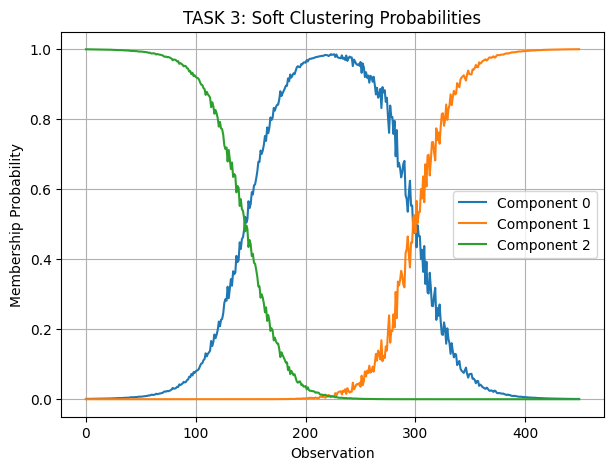

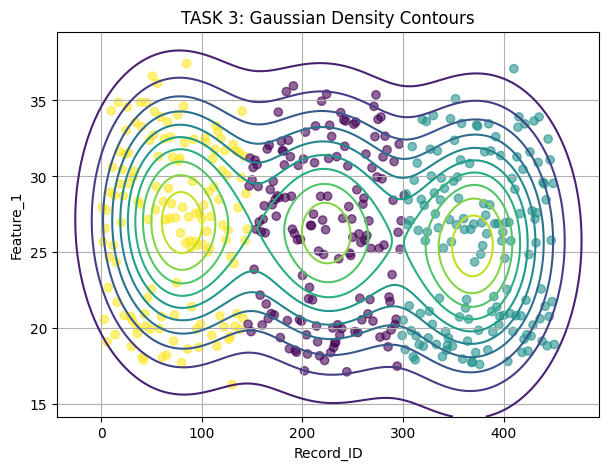

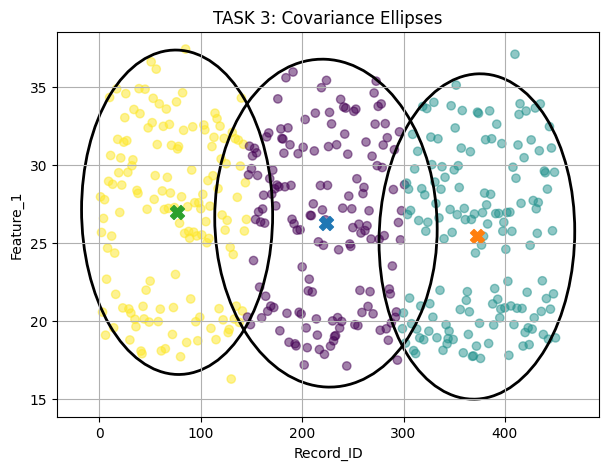

## TASK 4: EM CONVERGENCE AND COMPONENT SELECTION

**Log-Likelihood Results**

,Max_Iterations,Log_Likelihood
0,1,-4164.538549
1,2,-4163.447221
2,5,-4162.841434
3,10,-4162.841434
4,20,-4162.841434
5,50,-4162.841434
6,100,-4162.841434


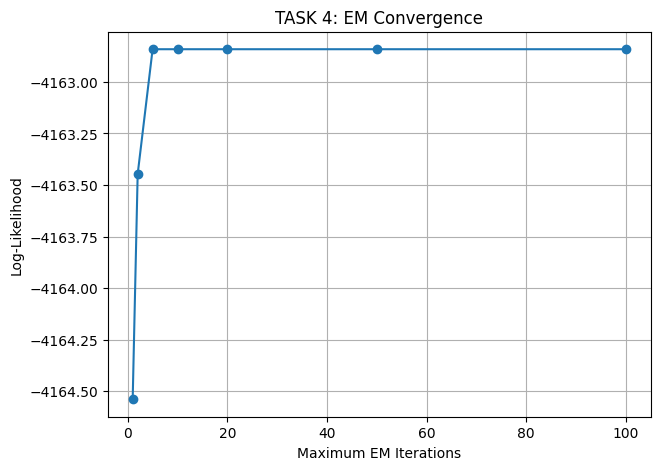

**AIC and BIC Results**

,Components,AIC,BIC
0,1,8432.913615,8453.459853
1,2,8376.382563,8421.584287
2,3,8359.682867,8429.540076
3,4,8355.805366,8450.318060
4,5,8355.893613,8475.061793
5,6,8361.007722,8504.831387
6,7,8363.637762,8532.116913
7,8,8375.391295,8568.525932


Best Component Count by AIC: 4
Best Component Count by BIC: 2


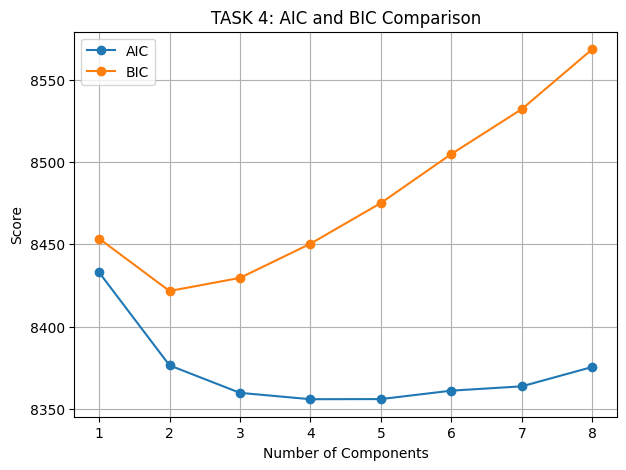

## TASK 5: COMPARE GMM WITH K-MEANS

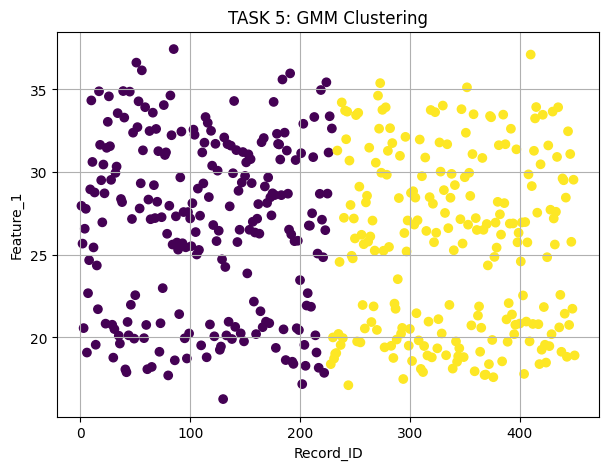

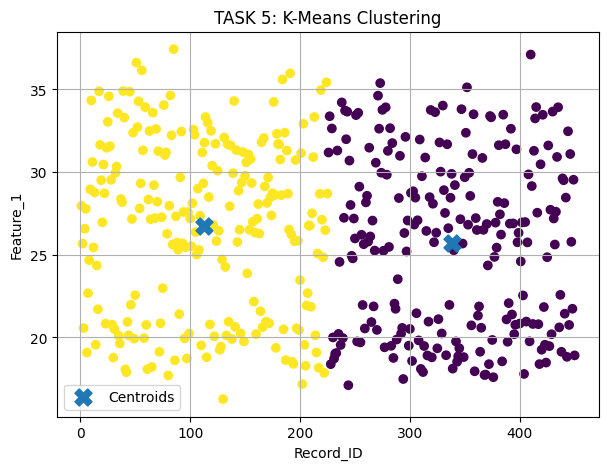

**Silhouette Score Comparison**

,Method,Silhouette_Score
0,GMM,0.621605
1,K-Means,0.621793


## TASK 6: NEW OBSERVATIONS AND MODEL UNDERSTANDING

**New Observations and Predicted Probabilities**

,Record_ID,Feature_1,Predicted_Component,Confidence,Component_0_Probability,Component_1_Probability
0,1.0,16.274000,0,0.999913,0.999913,0.000087
1,225.5,26.209673,0,0.512598,0.512598,0.487402
2,450.0,37.428000,1,0.999926,0.000074,0.999926


**Covariance Type Comparison**

,Covariance_Type,Log_Likelihood,AIC,BIC,Silhouette_Score
0,full,-4177.191282,8376.382563,8421.584287,0.621605
1,tied,-4177.234248,8370.468495,8403.342476,0.621300
2,diag,-4177.273406,8372.546813,8409.530041,0.620150
3,spherical,-5020.388447,10054.776893,10083.541626,0.621786


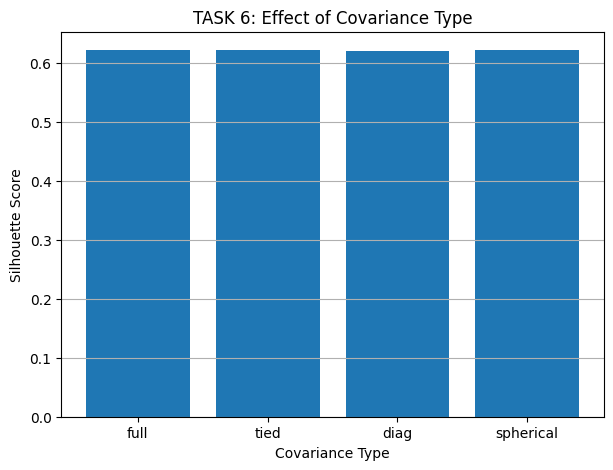

In [7]:

# GAUSSIAN MIXTURE MODEL (GMM) AND EM ALGORITHM

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from IPython.display import display, Markdown
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from matplotlib.patches import Ellipse


def task(title):
    display(Markdown(f"## {title}"))


# ============================================================
# TASK 1: LOAD AND UNDERSTAND THE DATASET
# ============================================================

task("TASK 1: LOAD AND UNDERSTAND THE DATASET")

uploaded = files.upload()
file_name = next(iter(uploaded))

if file_name.endswith('.csv'):
    df = pd.read_csv(file_name)
elif file_name.endswith(('.xlsx', '.xls')):
    df = pd.read_excel(file_name)
else:
    raise ValueError("Upload a CSV or Excel file.")

display(Markdown("**First 10 Records**"))
display(df.head(10))

display(Markdown("**Dataset Shape**"))
display(pd.DataFrame({
    'Rows': [df.shape[0]],
    'Columns': [df.shape[1]]
}))

display(Markdown("**Descriptive Statistics**"))
display(df.describe())

numeric_features = df.select_dtypes(include=np.number).columns.tolist()

if len(numeric_features) < 2:
    raise ValueError("Dataset must have at least two numeric features.")

feature1, feature2 = numeric_features[:2]
X = df[[feature1, feature2]].copy()

display(Markdown(f"**Input Features:** {feature1}, {feature2}"))

plt.figure(figsize=(7, 5))
plt.scatter(X[feature1], X[feature2])
plt.xlabel(feature1)
plt.ylabel(feature2)
plt.title("TASK 1: Scatter Plot Before Clustering")
plt.grid(True)
plt.show()


# ============================================================
# TASK 2: APPLY GMM CLUSTERING
# ============================================================

task("TASK 2: APPLY GMM CLUSTERING")

gmm = GaussianMixture(
    n_components=3,
    covariance_type='full',
    random_state=42
)
gmm.fit(X)
gmm_labels = gmm.predict(X)
df['GMM_Cluster'] = gmm_labels

display(Markdown("**Cluster Assignments**"))
display(df[[feature1, feature2, 'GMM_Cluster']])

plt.figure(figsize=(7, 5))
for i in range(3):
    plt.scatter(
        X.loc[gmm_labels == i, feature1],
        X.loc[gmm_labels == i, feature2],
        label=f'Cluster {i}'
    )
plt.xlabel(feature1)
plt.ylabel(feature2)
plt.title("TASK 2: GMM Clustering")
plt.legend()
plt.grid(True)
plt.show()

display(Markdown("**Gaussian Means**"))
display(pd.DataFrame(gmm.means_, columns=[feature1, feature2]))

display(Markdown("**Covariance Matrices**"))
for i, covariance in enumerate(gmm.covariances_):
    display(Markdown(f"**Component {i}**"))
    display(pd.DataFrame(
        covariance,
        columns=[feature1, feature2],
        index=[feature1, feature2]
    ))

display(Markdown("**Mixture Weights**"))
display(pd.DataFrame({
    'Component': range(3),
    'Weight': gmm.weights_
}))
print("Sum of Weights:", round(gmm.weights_.sum(), 4))


# ============================================================
# TASK 3: SOFT CLUSTERING AND GAUSSIAN DISTRIBUTIONS
# ============================================================

task("TASK 3: SOFT CLUSTERING AND GAUSSIAN DISTRIBUTIONS")

probabilities = gmm.predict_proba(X)

probability_df = pd.DataFrame(
    probabilities,
    columns=['Component_0', 'Component_1', 'Component_2']
)

display(Markdown("**Membership Probabilities — First 10 Observations**"))
display(probability_df.head(10))

probability_df['Maximum_Probability'] = probabilities.max(axis=1)

display(Markdown("**Uncertain Observations (Maximum Probability < 0.60)**"))
display(probability_df[probability_df['Maximum_Probability'] < 0.60])

plt.figure(figsize=(7, 5))
for i in range(3):
    plt.plot(probabilities[:, i], label=f'Component {i}')
plt.xlabel("Observation")
plt.ylabel("Membership Probability")
plt.title("TASK 3: Soft Clustering Probabilities")
plt.legend()
plt.grid(True)
plt.show()

x_min, x_max = X[feature1].min(), X[feature1].max()
y_min, y_max = X[feature2].min(), X[feature2].max()

x_margin = (x_max - x_min) * 0.1 or 0.1
y_margin = (y_max - y_min) * 0.1 or 0.1

xx, yy = np.meshgrid(
    np.linspace(x_min - x_margin, x_max + x_margin, 150),
    np.linspace(y_min - y_margin, y_max + y_margin, 150)
)

grid = np.column_stack([xx.ravel(), yy.ravel()])
density = np.exp(gmm.score_samples(grid)).reshape(xx.shape)

plt.figure(figsize=(7, 5))
plt.contour(xx, yy, density, levels=10)
plt.scatter(X[feature1], X[feature2], c=gmm_labels, alpha=0.6)
plt.xlabel(feature1)
plt.ylabel(feature2)
plt.title("TASK 3: Gaussian Density Contours")
plt.grid(True)
plt.show()

plt.figure(figsize=(7, 5))
plt.scatter(X[feature1], X[feature2], c=gmm_labels, alpha=0.5)

for i in range(3):
    mean = gmm.means_[i]
    covariance = gmm.covariances_[i]

    eigenvalues, eigenvectors = np.linalg.eigh(covariance)
    order = eigenvalues.argsort()[::-1]
    eigenvalues = eigenvalues[order]
    eigenvectors = eigenvectors[:, order]

    angle = np.degrees(np.arctan2(
        eigenvectors[1, 0], eigenvectors[0, 0]
    ))

    ellipse = Ellipse(
        xy=mean,
        width=4 * np.sqrt(max(eigenvalues[0], 0)),
        height=4 * np.sqrt(max(eigenvalues[1], 0)),
        angle=angle,
        fill=False,
        linewidth=2
    )
    plt.gca().add_patch(ellipse)
    plt.scatter(mean[0], mean[1], marker='X', s=100)

plt.xlabel(feature1)
plt.ylabel(feature2)
plt.title("TASK 3: Covariance Ellipses")
plt.grid(True)
plt.show()


# ============================================================
# TASK 4: EM CONVERGENCE AND COMPONENT SELECTION
# ============================================================

task("TASK 4: EM CONVERGENCE AND COMPONENT SELECTION")

iteration_values = [1, 2, 5, 10, 20, 50, 100]
log_likelihoods = []

for max_iter in iteration_values:
    model = GaussianMixture(
        n_components=3,
        random_state=42,
        max_iter=max_iter
    )
    model.fit(X)
    log_likelihoods.append(model.score(X) * len(X))

display(Markdown("**Log-Likelihood Results**"))
display(pd.DataFrame({
    'Max_Iterations': iteration_values,
    'Log_Likelihood': log_likelihoods
}))

plt.figure(figsize=(7, 5))
plt.plot(iteration_values, log_likelihoods, marker='o')
plt.xlabel("Maximum EM Iterations")
plt.ylabel("Log-Likelihood")
plt.title("TASK 4: EM Convergence")
plt.grid(True)
plt.show()

components = list(range(1, 9))
aic_values, bic_values = [], []

for k in components:
    model = GaussianMixture(
        n_components=k,
        random_state=42,
        max_iter=100
    )
    model.fit(X)
    aic_values.append(model.aic(X))
    bic_values.append(model.bic(X))

display(Markdown("**AIC and BIC Results**"))
display(pd.DataFrame({
    'Components': components,
    'AIC': aic_values,
    'BIC': bic_values
}))

best_aic = components[np.argmin(aic_values)]
best_bic = components[np.argmin(bic_values)]

print("Best Component Count by AIC:", best_aic)
print("Best Component Count by BIC:", best_bic)

plt.figure(figsize=(7, 5))
plt.plot(components, aic_values, marker='o', label='AIC')
plt.plot(components, bic_values, marker='o', label='BIC')
plt.xlabel("Number of Components")
plt.ylabel("Score")
plt.title("TASK 4: AIC and BIC Comparison")
plt.xticks(components)
plt.legend()
plt.grid(True)
plt.show()


# ============================================================
# TASK 5: GMM VS K-MEANS
# ============================================================

task("TASK 5: COMPARE GMM WITH K-MEANS")

selected_k = best_bic

gmm_selected = GaussianMixture(
    n_components=selected_k,
    random_state=42
)
gmm_selected.fit(X)
gmm_selected_labels = gmm_selected.predict(X)

kmeans = KMeans(
    n_clusters=selected_k,
    random_state=42,
    n_init=10
)
kmeans_labels = kmeans.fit_predict(X)

plt.figure(figsize=(7, 5))
plt.scatter(X[feature1], X[feature2], c=gmm_selected_labels)
plt.xlabel(feature1)
plt.ylabel(feature2)
plt.title("TASK 5: GMM Clustering")
plt.grid(True)
plt.show()

plt.figure(figsize=(7, 5))
plt.scatter(X[feature1], X[feature2], c=kmeans_labels)
plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker='X',
    s=150,
    label='Centroids'
)
plt.xlabel(feature1)
plt.ylabel(feature2)
plt.title("TASK 5: K-Means Clustering")
plt.legend()
plt.grid(True)
plt.show()

display(Markdown("**Silhouette Score Comparison**"))
display(pd.DataFrame({
    'Method': ['GMM', 'K-Means'],
    'Silhouette_Score': [
        silhouette_score(X, gmm_selected_labels),
        silhouette_score(X, kmeans_labels)
    ]
}))


# ============================================================
# TASK 6: NEW OBSERVATIONS AND COVARIANCE TYPES
# ============================================================

task("TASK 6: NEW OBSERVATIONS AND MODEL UNDERSTANDING")

new_observations = pd.DataFrame({
    feature1: [X[feature1].min(), X[feature1].mean(), X[feature1].max()],
    feature2: [X[feature2].min(), X[feature2].mean(), X[feature2].max()]
})

new_labels = gmm_selected.predict(new_observations)
new_probabilities = gmm_selected.predict_proba(new_observations)

new_results = new_observations.copy()
new_results['Predicted_Component'] = new_labels
new_results['Confidence'] = new_probabilities.max(axis=1)

for i in range(selected_k):
    new_results[f'Component_{i}_Probability'] = new_probabilities[:, i]

display(Markdown("**New Observations and Predicted Probabilities**"))
display(new_results)

covariance_types = ['full', 'tied', 'diag', 'spherical']
covariance_results = []

for covariance_type in covariance_types:
    model = GaussianMixture(
        n_components=selected_k,
        covariance_type=covariance_type,
        random_state=42
    )
    model.fit(X)
    labels = model.predict(X)

    covariance_results.append({
        'Covariance_Type': covariance_type,
        'Log_Likelihood': model.score(X) * len(X),
        'AIC': model.aic(X),
        'BIC': model.bic(X),
        'Silhouette_Score': silhouette_score(X, labels)
    })

covariance_df = pd.DataFrame(covariance_results)

display(Markdown("**Covariance Type Comparison**"))
display(covariance_df)

plt.figure(figsize=(7, 5))
plt.bar(
    covariance_df['Covariance_Type'],
    covariance_df['Silhouette_Score']
)
plt.xlabel("Covariance Type")
plt.ylabel("Silhouette Score")
plt.title("TASK 6: Effect of Covariance Type")
plt.grid(axis='y')
plt.show()
